In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Marketing Campaign Analysis")
print("Environment is ready!")

Marketing Campaign Analysis
Environment is ready!


In [3]:
df = pd.read_csv("../Dataset/marketing_campaign.csv", sep="\t")

df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [4]:
print("DATASET SHAPE:", df.shape)

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nDUPLICATE ROWS:", df.duplicated().sum())

DATASET SHAPE: (2240, 29)

COLUMN NAMES:
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']

DATA TYPES:
ID                       int64
Year_Birth               int64
Education                  str
Marital_Status             str
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer                str
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
N

In [5]:
# 1. Remove duplicate records
df = df.drop_duplicates()

# 2. Convert income into numeric format
df["Income"] = pd.to_numeric(df["Income"], errors="coerce")

# 3. Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# 4. Fill missing income with median income
df["Income"] = df["Income"].fillna(df["Income"].median())

# 5. Convert date column
df["Dt_Customer"] = pd.to_datetime(
    df["Dt_Customer"], dayfirst=True, errors="coerce"
)

# 6. Confirm cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nFinal dataset shape:", df.shape)

Missing values before cleaning:
ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

Missing values after cleaning:
ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome           

###Customer Spending Analysis

In [6]:
df["Total_Spending"] = (
    df["MntWines"] +
    df["MntFruits"] +
    df["MntMeatProducts"] +
    df["MntFishProducts"] +
    df["MntSweetProducts"] +
    df["MntGoldProds"]
)

df[["ID", "Total_Spending"]].head()

,ID,Total_Spending
0,5524,1617
1,2174,27
2,4141,776
3,6182,53
4,5324,422


##Customer Spending KPIs

In [7]:
total_customers = df["ID"].nunique()

total_revenue = df["Total_Spending"].sum()

average_spending = df["Total_Spending"].mean()

highest_spending = df["Total_Spending"].max()

print("Total Customers:", total_customers)
print("Total Revenue:", total_revenue)
print("Average Customer Spending:", average_spending)
print("Highest Customer Spending:", highest_spending)

Total Customers: 2240
Total Revenue: 1356988
Average Customer Spending: 605.7982142857143
Highest Customer Spending: 2525


##Best-Selling Product Category

In [8]:
product_columns = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

category_revenue = df[product_columns].sum().sort_values(ascending=False)

print(category_revenue)

MntWines            680816
MntMeatProducts     373968
MntGoldProds         98609
MntFishProducts      84057
MntSweetProducts     60621
MntFruits            58917
dtype: int64


##Product Category Spending

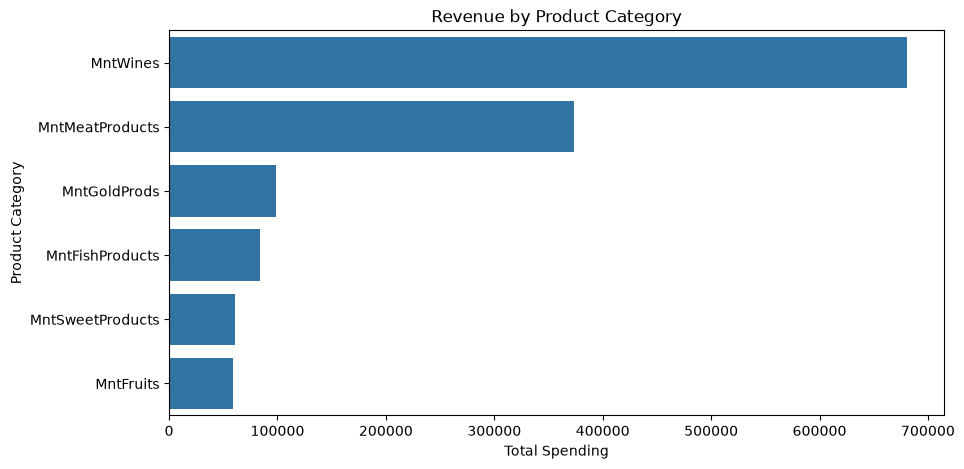

In [9]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_revenue.values,
    y=category_revenue.index
)

plt.title("Revenue by Product Category")
plt.xlabel("Total Spending")
plt.ylabel("Product Category")
plt.show()

##campaign acceptance

In [10]:
campaign_columns = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5"
]

campaign_acceptance = df[campaign_columns].sum()

print("Campaign Acceptance:")
print(campaign_acceptance)

Campaign Acceptance:
AcceptedCmp1    144
AcceptedCmp2     30
AcceptedCmp3    163
AcceptedCmp4    167
AcceptedCmp5    163
dtype: int64


##campaign acceptance percentage

In [ ]:
total_customers = len(df)

campaign_percentage = (campaign_acceptance / total_customers) * 100

print("Campaign Acceptance Percentage:")
print(campaign_percentage.round(2))


Campaign Acceptance Percentage:
AcceptedCmp1    6.43
AcceptedCmp2    1.34
AcceptedCmp3    7.28
AcceptedCmp4    7.46
AcceptedCmp5    7.28
dtype: float64


##Visualise campaign performance

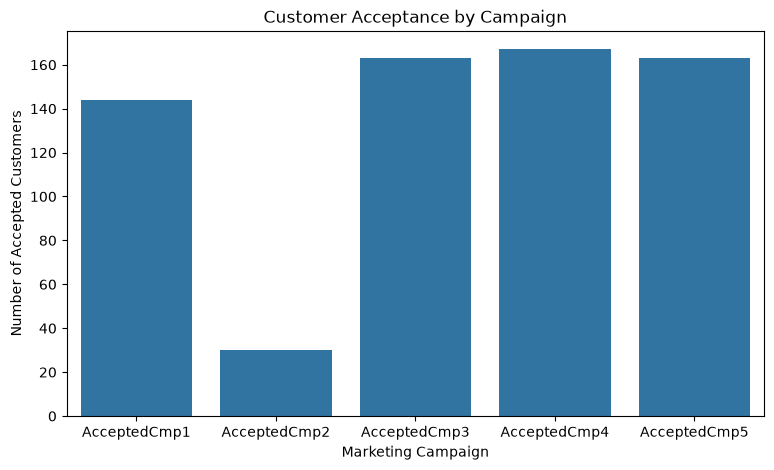

In [12]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=campaign_acceptance.index,
    y=campaign_acceptance.values
)

plt.title("Customer Acceptance by Campaign")
plt.xlabel("Marketing Campaign")
plt.ylabel("Number of Accepted Customers")

plt.show()

##the best-performing campaign

In [13]:
best_campaign = campaign_acceptance.idxmax()
best_acceptance = campaign_acceptance.max()

print("Best Performing Campaign:", best_campaign)
print("Customers Accepted:", best_acceptance)

Best Performing Campaign: AcceptedCmp4
Customers Accepted: 167


#Customer Demographics Analysis.

##Customer age

In [14]:
from datetime import datetime

current_year = datetime.now().year

df["Age"] = current_year - df["Year_Birth"]

print(df["Age"].describe())

count    2240.000000
mean       57.194196
std        11.984069
min        30.000000
25%        49.000000
50%        56.000000
75%        67.000000
max       133.000000
Name: Age, dtype: float64


##Analyse age groups

In [15]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 30, 40, 50, 60, 100],
    labels=["Under 30", "30-40", "40-50", "50-60", "Above 60"]
)

age_distribution = df["Age_Group"].value_counts().sort_index()

print(age_distribution)

Age_Group
Under 30      2
30-40       187
40-50       506
50-60       685
Above 60    857
Name: count, dtype: int64


##Visualise customer age groups

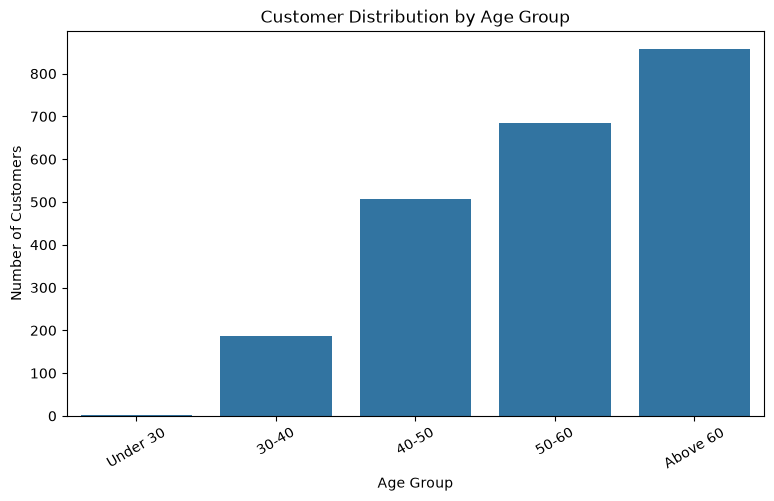

In [16]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Age_Group"
)

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.show()

##Analyse education levels

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64


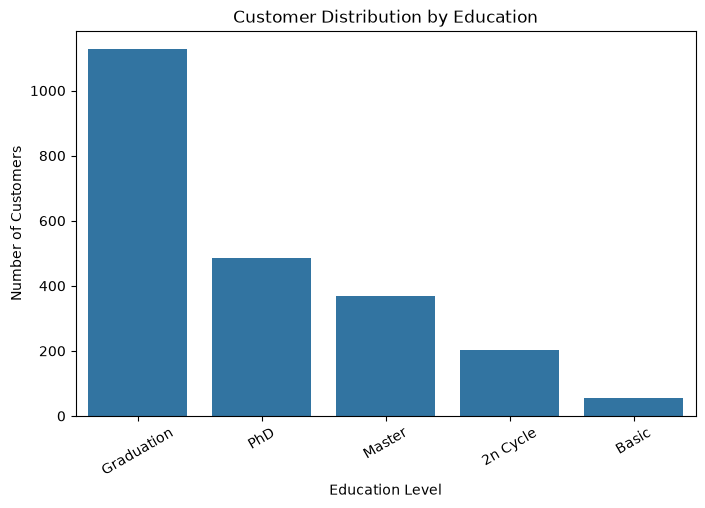

In [17]:
education_distribution = df["Education"].value_counts()

print(education_distribution)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Education",
    order=education_distribution.index
)

plt.title("Customer Distribution by Education")
plt.xlabel("Education Level")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.show()

##Analyse income by education

In [18]:
income_by_education = df.groupby("Education")["Income"].mean().sort_values(ascending=False)

print(income_by_education.round(2))

Education
PhD           56096.30
Master        52896.78
Graduation    52707.31
2n Cycle      47688.58
Basic         20306.26
Name: Income, dtype: float64


##Purchase Channel Analysis

In [20]:
#Calculate total purchases by channel

channel_columns = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

channel_performance = df[channel_columns].sum().sort_values(ascending=False)

print(channel_performance)

NumStorePurchases      12970
NumWebPurchases         9150
NumCatalogPurchases     5963
dtype: int64


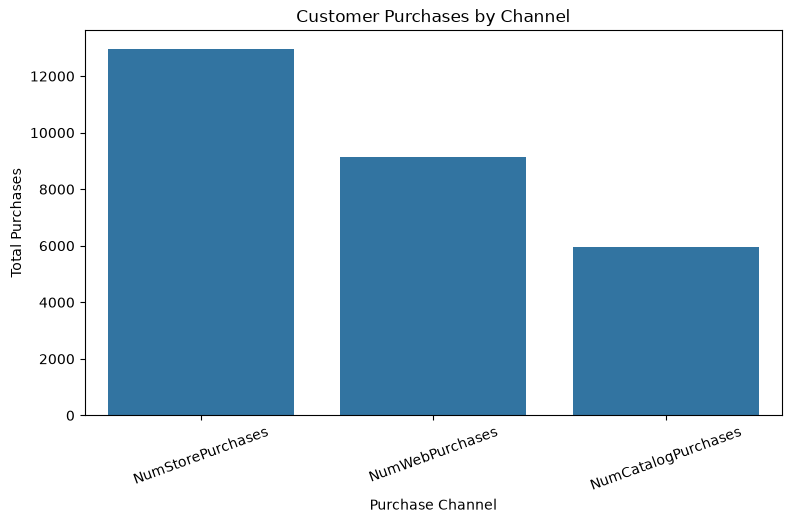

In [21]:
#Visualise purchase channels

plt.figure(figsize=(9, 5))

sns.barplot(
    x=channel_performance.index,
    y=channel_performance.values
)

plt.title("Customer Purchases by Channel")
plt.xlabel("Purchase Channel")
plt.ylabel("Total Purchases")
plt.xticks(rotation=20)

plt.show()

In [22]:
#Compare website visits with web purchases

print("Average Website Visits:",
      df["NumWebVisitsMonth"].mean())

print("Average Website Purchases:",
      df["NumWebPurchases"].mean())

Average Website Visits: 5.316517857142857
Average Website Purchases: 4.084821428571429


In [23]:
#Analyse purchase behaviour by age group

channel_by_age = df.groupby("Age_Group", observed=True)[
    channel_columns
].mean()

print(channel_by_age.round(2))

           NumWebPurchases  NumCatalogPurchases  NumStorePurchases
Age_Group                                                         
Under 30              2.00                 0.50               2.50
30-40                 3.45                 2.74               5.62
40-50                 3.64                 2.19               5.23
50-60                 4.05                 2.34               5.56
Above 60              4.52                 3.19               6.36


In [24]:
#Count campaign responses

response_counts = df["Response"].value_counts()

print("Campaign Response Counts:")
print(response_counts)

Campaign Response Counts:
Response
0    1906
1     334
Name: count, dtype: int64


In [25]:
#Calculate acceptance rate

total_customers = len(df)

accepted_customers = (df["Response"] == 1).sum()

acceptance_rate = (accepted_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Accepted:", accepted_customers)
print("Acceptance Rate:", round(acceptance_rate, 2), "%")

Total Customers: 2240
Accepted: 334
Acceptance Rate: 14.91 %


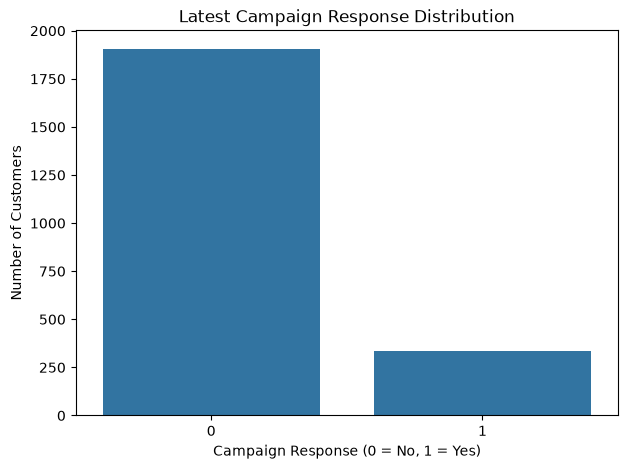

In [27]:
#Visualise campaign responses

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Response")

plt.title("Latest Campaign Response Distribution")
plt.xlabel("Campaign Response (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

In [28]:
#Compare campaign acceptance by education

response_by_education = df.groupby("Education")["Response"].mean() * 100

print("Acceptance Rate by Education:")
print(response_by_education.round(2))

Acceptance Rate by Education:
Education
2n Cycle      10.84
Basic          3.70
Graduation    13.49
Master        15.41
PhD           20.78
Name: Response, dtype: float64


In [29]:
#Compare acceptance by age group

response_by_age = df.groupby("Age_Group", observed=True)["Response"].mean() * 100

print("Acceptance Rate by Age Group:")
print(response_by_age.round(2))

Acceptance Rate by Age Group:
Age_Group
Under 30    50.00
30-40       16.58
40-50       15.22
50-60       15.47
Above 60    13.89
Name: Response, dtype: float64


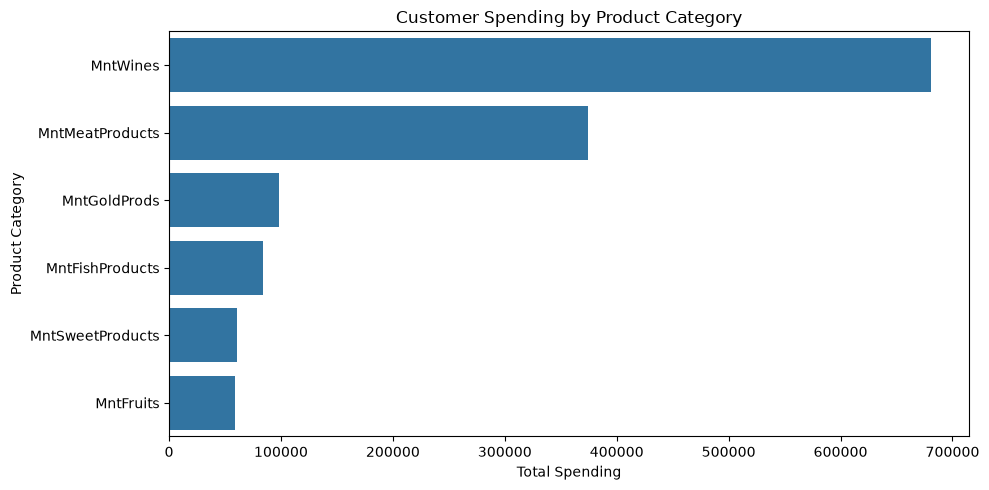

In [30]:
#Customer spending by product category

plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_revenue.values,
    y=category_revenue.index
)

plt.title("Customer Spending by Product Category")
plt.xlabel("Total Spending")
plt.ylabel("Product Category")

plt.tight_layout()
plt.savefig("../Visualizations/product_category_spending.png")
plt.show()

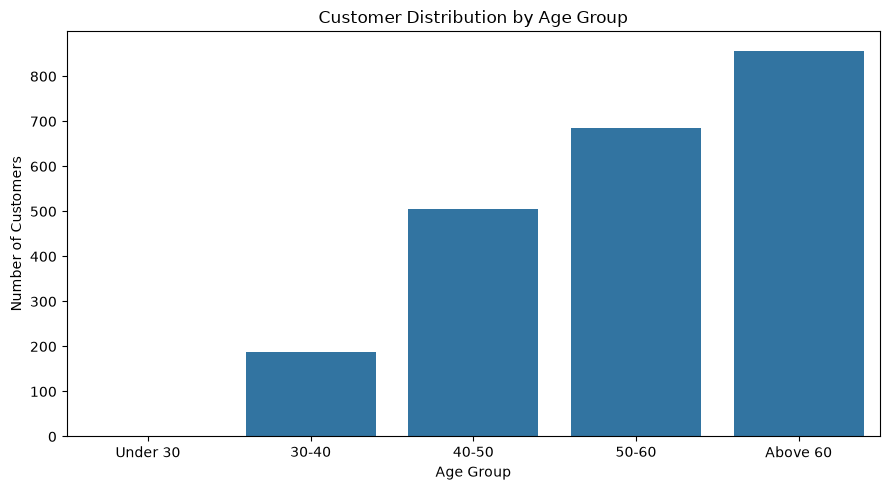

In [31]:
#Customer age distribution

plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Age_Group")

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig("../Visualizations/customer_age_distribution.png")
plt.show()

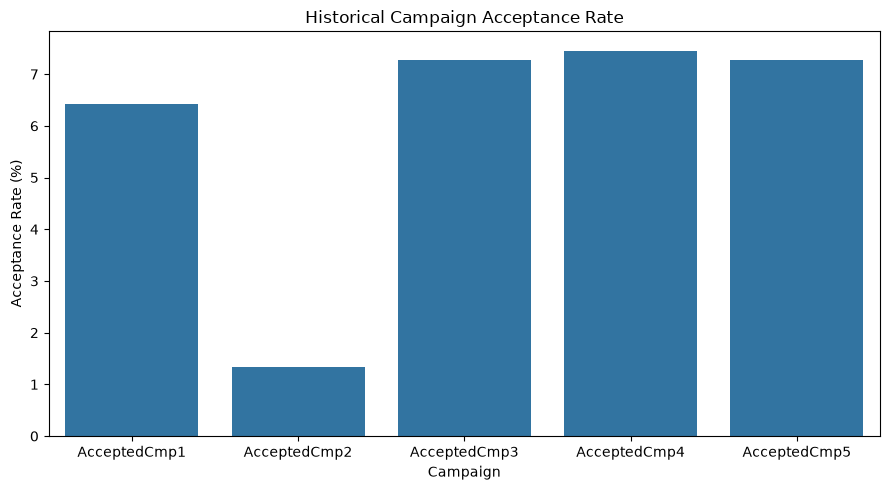

In [32]:
#Marketing campaign performance

plt.figure(figsize=(9, 5))

sns.barplot(
    x=campaign_percentage.index,
    y=campaign_percentage.values
)

plt.title("Historical Campaign Acceptance Rate")
plt.xlabel("Campaign")
plt.ylabel("Acceptance Rate (%)")

plt.tight_layout()
plt.savefig("../Visualizations/campaign_acceptance.png")
plt.show()

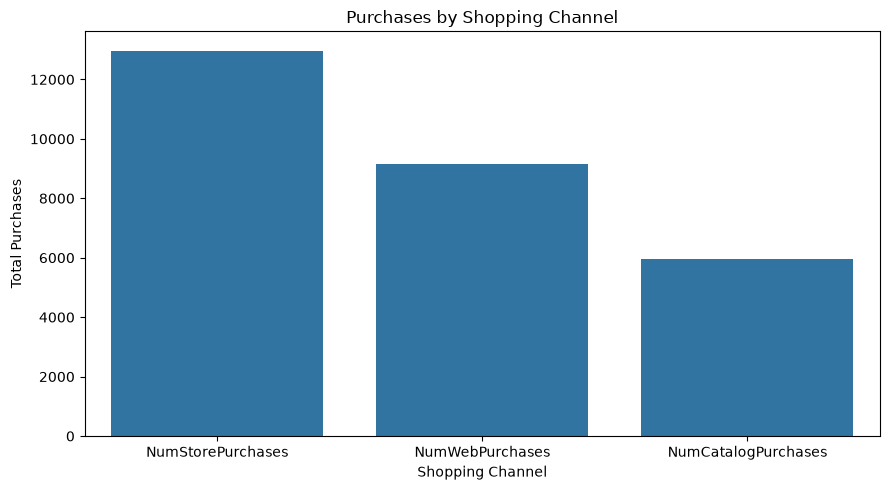

In [34]:
#Purchase channel comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    x=channel_performance.index,
    y=channel_performance.values
)

plt.title("Purchases by Shopping Channel")
plt.xlabel("Shopping Channel")
plt.ylabel("Total Purchases")

plt.tight_layout()
plt.savefig("../Visualizations/purchase_channel_performance.png")
plt.show()

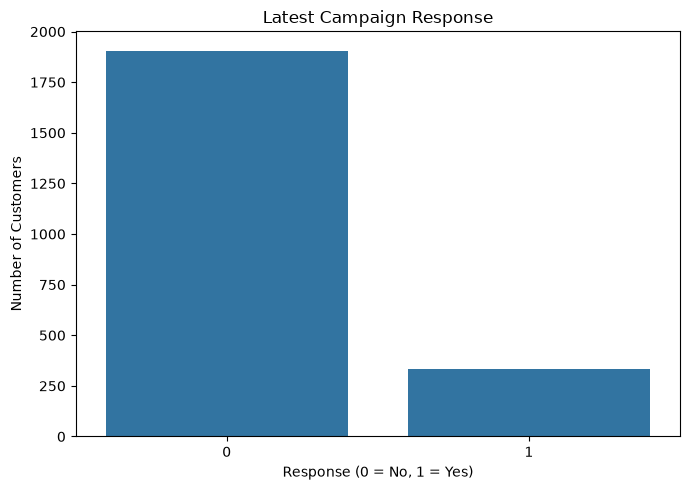

In [35]:
#Latest campaign response

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Response")

plt.title("Latest Campaign Response")
plt.xlabel("Response (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig("../Visualizations/latest_campaign_response.png")
plt.show()

In [36]:
#Generate a business KPI summary

business_summary = {
    "Total Customers": df["ID"].nunique(),
    "Total Customer Spending": df["Total_Spending"].sum(),
    "Average Customer Spending": df["Total_Spending"].mean(),
    "Latest Campaign Acceptance Rate (%)": df["Response"].mean() * 100,
    "Average Customer Income": df["Income"].mean(),
    "Average Customer Age": df["Age"].mean()
}

for metric, value in business_summary.items():
    print(f"{metric}: {value:,.2f}")

Total Customers: 2,240.00
Total Customer Spending: 1,356,988.00
Average Customer Spending: 605.80
Latest Campaign Acceptance Rate (%): 14.91
Average Customer Income: 52,237.98
Average Customer Age: 57.19


In [37]:
print("PROJECT VALIDATION")
print("------------------")

print("Total Customers:", df["ID"].nunique())
print("Total Columns:", df.shape[1])
print("Total Spending:", round(df["Total_Spending"].sum(), 2))
print("Average Spending:", round(df["Total_Spending"].mean(), 2))
print("Latest Campaign Acceptance:", round(df["Response"].mean() * 100, 2), "%")

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nProject Analysis Completed!")

PROJECT VALIDATION
------------------
Total Customers: 2240
Total Columns: 32
Total Spending: 1356988
Average Spending: 605.8
Latest Campaign Acceptance: 14.91 %

Missing Values:
3

Project Analysis Completed!
